# CNRM-CM6-1 versus HadGEM3-GC31-LL: historical event depths and WK spectra

Compare **only these two historical simulations** over 1990–2010, using their
completed **2σ envelope event catalogs**. The supplied model names are interpreted
as the available CMIP6 IDs **CNRM-CM6-1** and **HadGEM3-GC31-LL**.

The first figure has one panel per wave family and two normalized apparent-depth
distributions. A full logarithmic view retains the broad tails. The final figure
compares the two models' symmetric and antisymmetric Wheeler–Kiladis-style
spectra on a common color scale.

## Inputs and visible choices

- CNRM-CM6-1 Historical: member `r1i1p1f2`, standard calendar.
- HadGEM3-GC31-LL Historical: member `r1i1p1f3`, 360-day calendar.
- Both use daily OLR on the project's NOAA 1-degree analysis grid. Native calendars and complete 1990–2010 records are retained.
- Depths come from the existing 2σ longitudinal Hilbert-envelope catalogs and branch-specific resting-background inversion. Sigma is model- and wave-specific. The threshold imposes a common relative cutoff.
- `DEPTH_SELECTION = "relaxed"` keeps successful, positive, dispersion-valid depths. Change it to `"screened"` to use the existing fit-quality flags. No fits are recomputed.
- Each curve divides by that run/wave's entire selected population. Events outside the displayed range remain in the denominator. No NOAA reference, ensemble pooling or energy weighting enters the depth comparison.
- WK spectra reuse the audited 96-day / 60-day-overlap mean powers over 15°S–15°N. Each model's spectrum is divided by its own shared symmetric/antisymmetric smoothed background (ten K and ten frequency 1-2-1 passes). This normalization is independent of the event threshold and is descriptive.

The two methods reduce latitude differently: event detection uses the northern
0–20° mean after symmetry projection over 20°S–20°N; the WK calculation averages
latitude powers over 15°S–15°N. The figures therefore compare related diagnostics
with different weightings.

In [1]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from src.paths import DATA_DIR

RUNS = [
    ("CNRM-CM6-1", "r1i1p1f2", "#2765a1"),
    ("HadGEM3-GC31-LL", "r1i1p1f3", "#bd6530"),
]
EXPERIMENT = "historical"
DETECTION_SIGMA = 2.0
DEPTH_SELECTION = "relaxed"  # "screened" applies the existing fit-quality flags.
WAVES = ["Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG"]
LABELS = {"Kelvin": "Kelvin", "MRG": "MRG", "n0EIG": "n=0 EIG", "n1ERW": "n=1 ER", "n1WIG": "n=1 WIG"}
SELECTION_LABELS = {"relaxed": "all valid-depth fits", "screened": "existing fit-quality subset"}
ROOT = DATA_DIR / "event_threshold_comparison"
HIST_INPUT = ROOT / "distributions_sigma2"
WK_INPUT = ROOT / "wave_event_komega_sigma2"
for folder in (HIST_INPUT, WK_INPUT):
    audit = json.loads((folder / "audit.json").read_text())
    assert audit["status"] == "complete" and audit["detection_sigma"] == DETECTION_SIGMA
all_counts = pd.read_csv(HIST_INPUT / "all_model_event_counts.csv.gz")
all_summary = pd.read_csv(ROOT / "catalog_summary.csv")
counts = pd.concat([
    all_counts.loc[all_counts.model.eq(model) & all_counts.member.eq(member)
                   & all_counts.experiment.eq(EXPERIMENT)]
    for model, member, _ in RUNS
], ignore_index=True)
summary = pd.concat([
    all_summary.loc[all_summary.model.eq(model) & all_summary.member.eq(member)
                     & all_summary.experiment.eq(EXPERIMENT)
                     & all_summary.detection_sigma.eq(DETECTION_SIGMA)]
    for model, member, _ in RUNS
], ignore_index=True)
assert len(counts) == 20 and counts.detection_sigma.eq(DETECTION_SIGMA).all()
assert len(summary) == 10 and not counts.duplicated(["model", "member", "wave_type", "selection"]).any()
record_ids = [f"{model}.{EXPERIMENT}.{member}" for model, member, _ in RUNS]
with xr.open_dataset(WK_INPUT / "histograms_and_wk.nc", decode_timedelta=False) as source:
    wk = source.sel(record=record_ids).load()
assert wk.sizes["record"] == 2 and wk.attrs["detection_sigma"] == DETECTION_SIGMA
assert wk.attrs["period"].startswith("1990--2010")

metadata = summary[["model", "experiment", "member", "calendar"]].drop_duplicates()
metadata = metadata.merge(counts[["model", "member", "record_days"]].drop_duplicates(),
                          on=["model", "member"], validate="one_to_one")
display(metadata)


,model,experiment,member,calendar,record_days
0,CNRM-CM6-1,historical,r1i1p1f2,standard,7670
1,HadGEM3-GC31-LL,historical,r1i1p1f3,360_day,7560


## Selected counts, medians and display coverage

The table identifies the exact population plotted for each wave. Both source
calendars span the same named years, while their numbers of daily samples differ.
The 1–100 m and 0.5–10,000 m coverage columns quantify the plotted fractions;
no tail is silently renormalized into the displayed interval.

In [2]:
rows = []
for model, member, _ in RUNS:
    for wave in WAVES:
        row = counts.loc[counts.model.eq(model) & counts.member.eq(member)
                         & counts.wave_type.eq(wave) & counts.selection.eq(DEPTH_SELECTION)].squeeze()
        reference = summary.loc[summary.model.eq(model) & summary.member.eq(member)
                                 & summary.wave.eq(wave)].squeeze()
        expected = reference.valid_depths if DEPTH_SELECTION == "relaxed" else reference.screened_events
        assert row.selected_events == expected and row.selected_events > 0
        prefix = "valid" if DEPTH_SELECTION == "relaxed" else "screened"
        rows.append(dict(
            model=model, wave=wave, selected_events=int(row.selected_events),
            median_h_m=reference[f"{prefix}_h_median_m"],
            p10_h_m=reference[f"{prefix}_h_p10_m"], p90_h_m=reference[f"{prefix}_h_p90_m"],
            in_1_to_100_m_pct=100*row[[f"count_{i:03d}m" for i in range(1, 100)]].sum()/row.selected_events,
            in_0p5_to_10000_m_pct=100*row[[f"log_count_{i:02d}" for i in range(50)]].sum()/row.selected_events,
        ))
depth_summary = pd.DataFrame(rows)
display(depth_summary.round(3))


,model,wave,selected_events,median_h_m,p10_h_m,p90_h_m,in_1_to_100_m_pct,in_0p5_to_10000_m_pct
0,CNRM-CM6-1,Kelvin,2453,9.355,5.368,15.988,100.000,100.000
1,CNRM-CM6-1,MRG,2193,30.350,6.621,259.680,77.337,99.134
2,CNRM-CM6-1,n0EIG,2884,6.679,4.037,10.791,100.000,100.000
3,CNRM-CM6-1,n1ERW,1081,17.437,8.344,30.446,100.000,100.000
4,CNRM-CM6-1,n1WIG,3261,6.691,4.474,9.831,100.000,100.000
5,HadGEM3-GC31-LL,Kelvin,2506,12.558,7.108,22.723,100.000,100.000
6,HadGEM3-GC31-LL,MRG,2129,35.584,6.843,291.296,75.059,99.342
7,HadGEM3-GC31-LL,n0EIG,2936,6.740,3.937,11.443,100.000,100.000
8,HadGEM3-GC31-LL,n1ERW,1084,17.580,8.462,35.990,100.000,100.000
9,HadGEM3-GC31-LL,n1WIG,3169,6.740,4.444,10.213,100.000,100.000


## Apparent equivalent-depth distributions, 1–100 m

Each panel compares the two historical runs for one wave family, using 1 m bins.
The y-axis gives percent of the full selected population per bin. The reference
is an apparent resting-background equivalent depth, conditional on the assigned
wave branch and event definition.

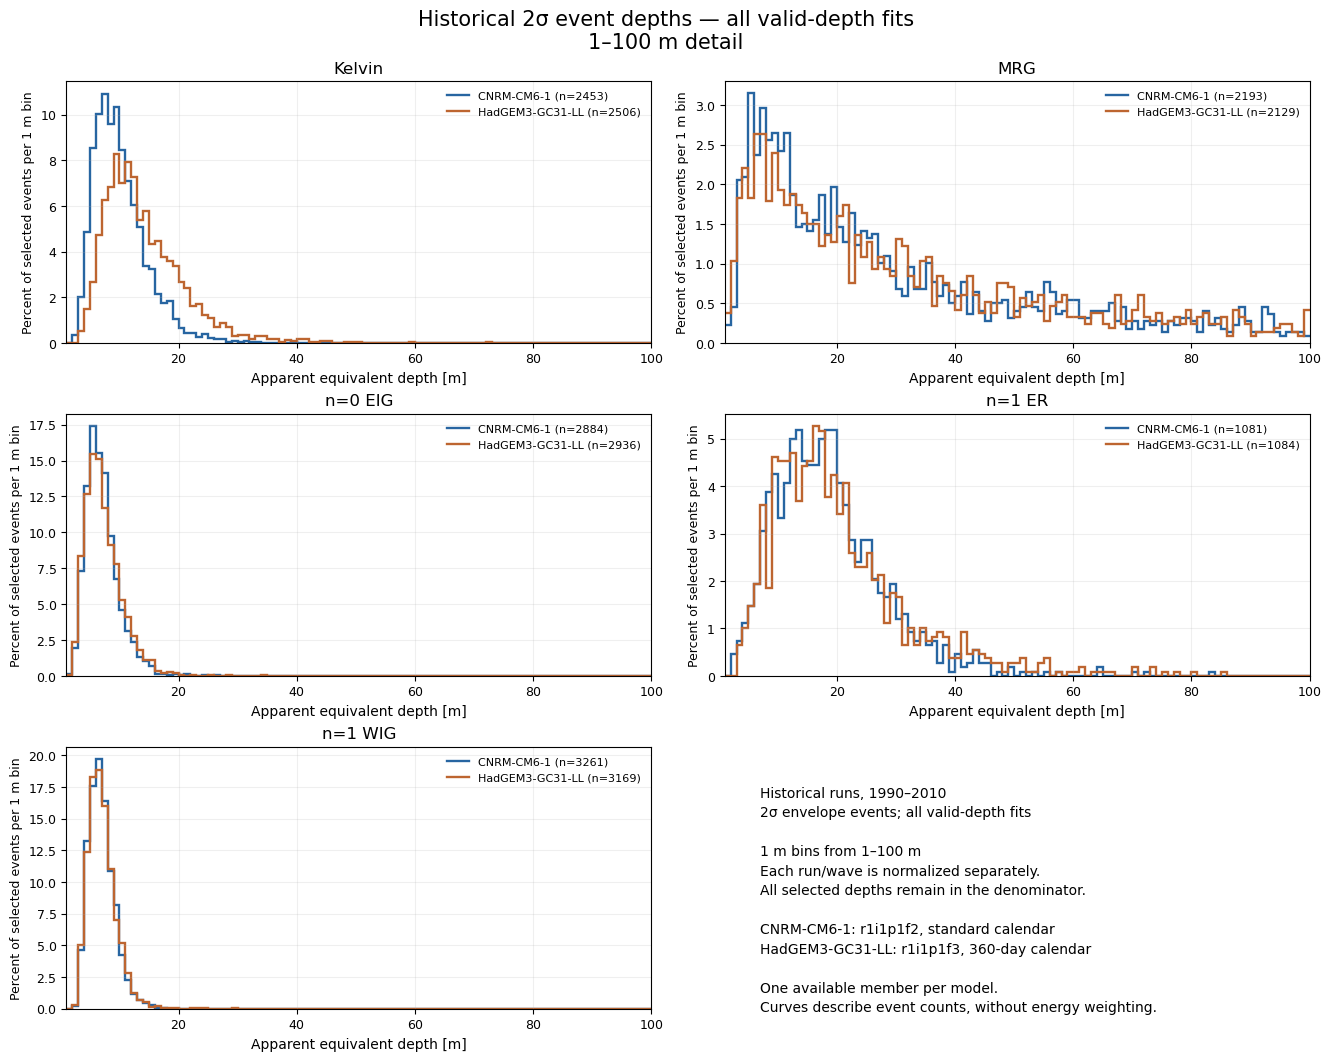

In [3]:
def plot_depth_panels(*, logarithmic=False):
    """Compare the two model depth distributions, one panel per wave family."""
    if logarithmic:
        edges = np.geomspace(.5, 10_000, 51)
        columns = [f"log_count_{i:02d}" for i in range(50)]
        widths = np.diff(np.log10(edges))
        ylabel = "Fraction of selected events per decade of depth"
    else:
        edges = np.arange(1., 101.)
        columns = [f"count_{i:03d}m" for i in range(1, 100)]
        ylabel = "Percent of selected events per 1 m bin"
    fig, axes = plt.subplots(3, 2, figsize=(13.2, 10.5), layout="constrained")
    for wave, ax in zip(WAVES, axes.flat):
        for model, member, color in RUNS:
            row = counts.loc[counts.model.eq(model) & counts.member.eq(member)
                             & counts.wave_type.eq(wave) & counts.selection.eq(DEPTH_SELECTION)].squeeze()
            values = row[columns].to_numpy(dtype=float) / row.selected_events
            values = values/widths if logarithmic else 100*values
            ax.stairs(values, edges, baseline=None, color=color, linewidth=1.7,
                      label=f"{model} (n={int(row.selected_events)})")
        if logarithmic:
            ax.set_xscale("log")
        ax.set(xlim=(edges[0], edges[-1]), ylim=(0, None),
               xlabel="Apparent equivalent depth [m]", ylabel=ylabel, title=LABELS[wave])
        ax.tick_params(labelsize=9)
        ax.xaxis.label.set_size(10)
        ax.yaxis.label.set_size(9)
        ax.legend(frameon=False, fontsize=8)
        ax.grid(alpha=.2)
    info = axes.flat[5]
    info.set_axis_off()
    width_text = "50 logarithmic bins from 0.5–10,000 m" if logarithmic else "1 m bins from 1–100 m"
    info.text(.06, .85,
        f"Historical runs, 1990–2010\n2σ envelope events; {SELECTION_LABELS[DEPTH_SELECTION]}\n\n"
        f"{width_text}\nEach run/wave is normalized separately.\n"
        "All selected depths remain in the denominator.\n\n"
        "CNRM-CM6-1: r1i1p1f2, standard calendar\n"
        "HadGEM3-GC31-LL: r1i1p1f3, 360-day calendar\n\n"
        "One available member per model.\nCurves describe event counts, without energy weighting.",
        transform=info.transAxes, fontsize=10, va="top", linespacing=1.5)
    scale = "full logarithmic view" if logarithmic else "1–100 m detail"
    fig.suptitle(f"Historical 2σ event depths — {SELECTION_LABELS[DEPTH_SELECTION]}\n{scale}", fontsize=15)
    plt.show()

plot_depth_panels(logarithmic=False)


## Full logarithmic view

This view exposes the broad MRG tail alongside the narrower other families.
It uses fractions per decade of depth, rather than percent per 1 m bin.
Values outside 0.5–10,000 m still remain in each curve's denominator.

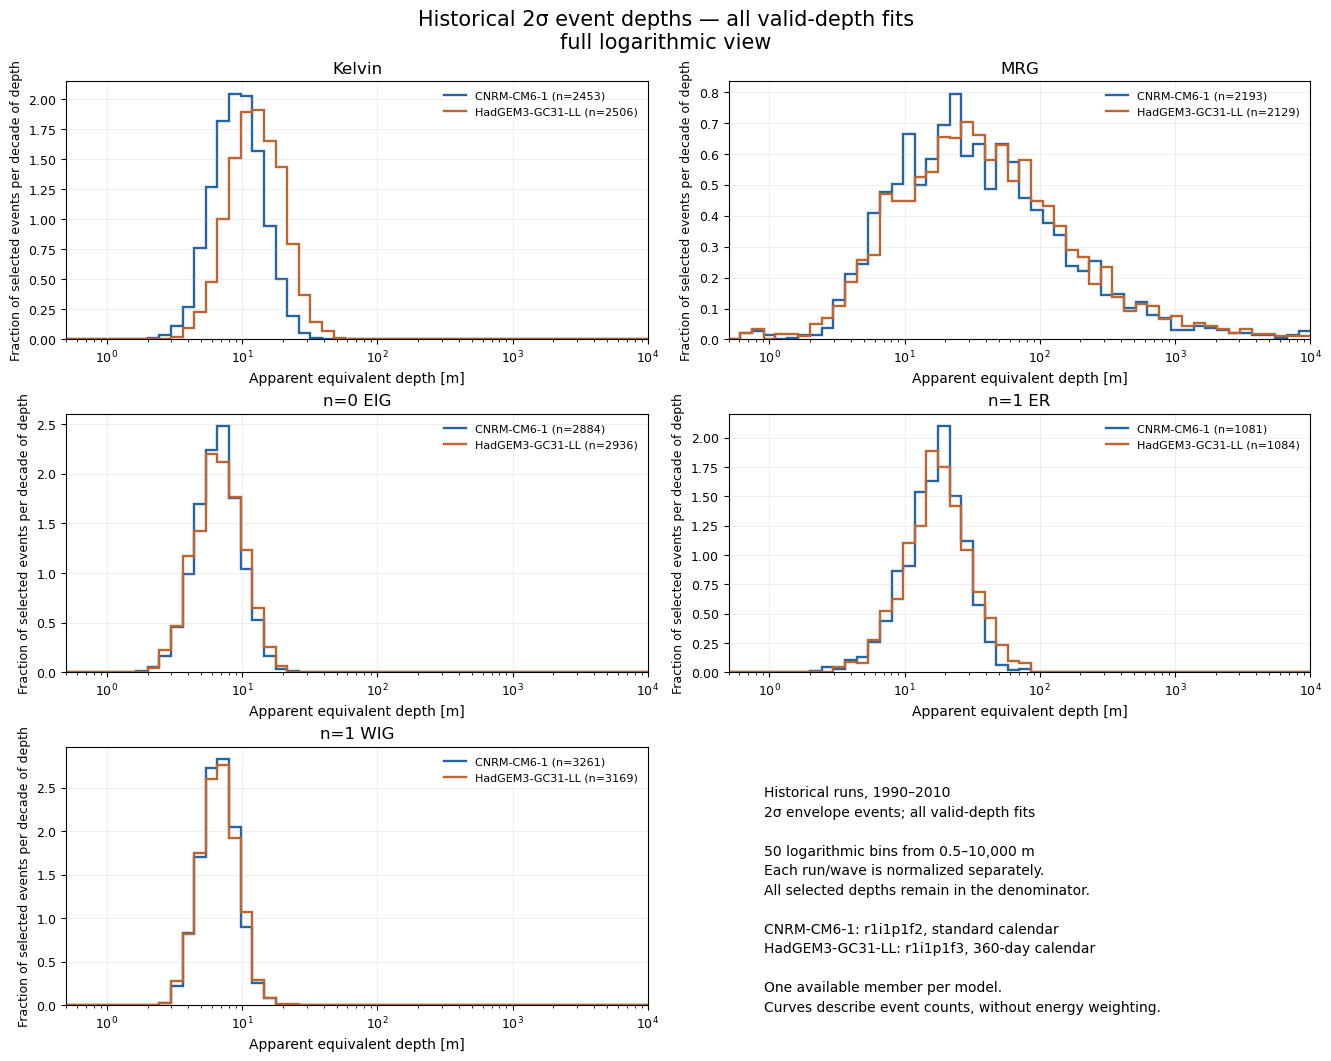

In [4]:
plot_depth_panels(logarithmic=True)


## Wheeler–Kiladis-style spectra

Rows are the two historical simulations; columns are symmetric and antisymmetric
OLR. Colors show **mean observed power / that model's own smoothed background**,
with one shared scale. Values below 1.1 are white; values above 2.5 saturate at the
upper extension. This emphasizes spectral enhancement and does not compare
absolute variance across models.

Red reference curves use 12/25/50 m and zero background wind. Symmetric panels
show Kelvin, n=1 ER and n=1 WIG; antisymmetric panels show MRG and n=0 EIG.
The curves are references, not filtering limits. The spectra are independent
of the event threshold, and exact daily Nyquist is excluded. A ratio contour
alone does not establish statistical significance or physical wave identity.

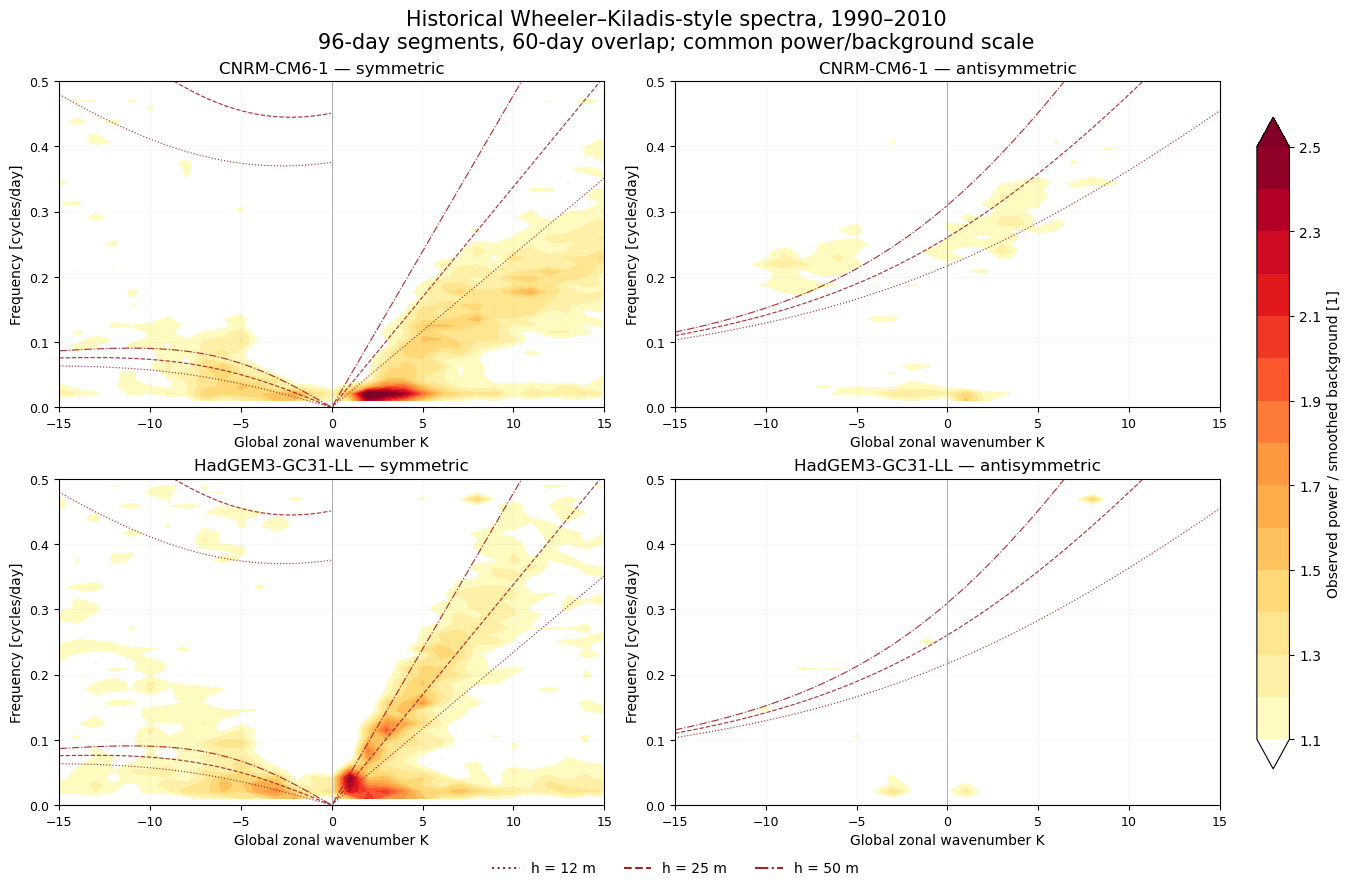

In [5]:
WK_LEVELS = np.arange(1.1, 2.51, .1)
DEPTH_STYLES = {12.: ":", 25.: "--", 50.: "-."}
RATIO_CMAP = plt.get_cmap("YlOrRd").copy()
RATIO_CMAP.set_under("white")
fig, axes = plt.subplots(2, 2, figsize=(13.4, 8.8), layout="constrained")
for r, (model, member, _) in enumerate(RUNS):
    record = f"{model}.{EXPERIMENT}.{member}"
    for c, symmetry in enumerate(("symmetric", "antisymmetric")):
        ax = axes[r, c]
        ratio = wk.wk_mean_power.sel(record=record, symmetry=symmetry) / wk.wk_background.sel(record=record)
        mesh = ax.contourf(wk.K.values, wk.wk_frequency.values, ratio.values,
                           levels=WK_LEVELS, cmap=RATIO_CMAP, extend="both")
        for wave in WAVES:
            if str(wk.wave_symmetry.sel(wave=wave).item()) != symmetry:
                continue
            for depth, linestyle in DEPTH_STYLES.items():
                curve = wk.curve_frequency.sel(wave=wave, equivalent_depth=depth)
                visible = np.where((curve > 0) & (curve < .5), curve, np.nan)
                ax.plot(wk.curve_K.values, visible, color="#a12424", linewidth=.85,
                        linestyle=linestyle, alpha=.9)
        ax.axvline(0, color=".65", linewidth=.65)
        ax.set(xlim=(-15, 15), ylim=(0, .5), xticks=np.arange(-15, 16, 5),
               yticks=np.arange(0, .51, .1), xlabel="Global zonal wavenumber K",
               ylabel="Frequency [cycles/day]", title=f"{model} — {symmetry}")
        ax.tick_params(labelsize=9)
        ax.grid(alpha=.12, linewidth=.5)
bar = fig.colorbar(mesh, ax=list(axes.flat), shrink=.9, pad=.025)
bar.set_label("Observed power / smoothed background [1]")
fig.legend(handles=[Line2D([], [], color="#a12424", linestyle=style, label=f"h = {depth:g} m")
                    for depth, style in DEPTH_STYLES.items()],
           loc="outside lower center", ncol=3, frameon=False, fontsize=10)
fig.suptitle("Historical Wheeler–Kiladis-style spectra, 1990–2010\n96-day segments, 60-day overlap; common power/background scale", fontsize=15)
plt.show()


## Interpretation and limits

For the default all-valid-depth selection, CNRM-CM6-1 has a lower Kelvin median
than HadGEM3-GC31-LL (9.36 versus 12.56 m). ER medians are close (17.44 versus
17.58 m), and EIG/WIG medians are near 6.7 m in both runs. MRG has broader tails;
its all-valid medians are 30.35 and 35.58 m. The summary table quantifies the
fractions outside each display window.

These are descriptive comparisons of one member per model. Changing the fit
selection can materially change the inferred-depth populations; the controls
and counts make that choice visible. The raw event thresholds are relative to
each model/wave's filtered variance. WK spectra and event-count distributions
have different weighting and latitude reductions, and a normalized spectral
peak does not itself identify a vertical mode or measure event-depth accuracy.
No Gaussian realizations, new significance selection or additional event fits
are used. No standalone figure files are written by this notebook.